In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, TwoSlopeNorm
from sklearn.decomposition import PCA
from pathlib import Path
import pandas as pd

In [40]:
FASTA_GEN = Path("./results/featuredca/jdomain_topt_ave_generation/jdomain.generated_fake.fasta")      

In [41]:
def read_fasta(path):
    """Return a list of (header without '>', sequence) in file order."""
    records, header, chunks = [], None, []
    with open(path) as fh:
        for line in fh:
            line = line.rstrip("\r\n")
            if line.startswith(">"):
                if header is not None:
                    records.append((header, "".join(chunks)))
                header, chunks = line[1:].strip(), []
            elif header is not None:
                chunks.append(line.strip())
            elif line.strip():
                raise ValueError(f"{path}: sequence data before the first '>' header")
    if header is not None:
        records.append((header, "".join(chunks)))
    return records


records = read_fasta(FASTA_GEN)
seqs = pd.DataFrame(records, columns=["header", "sequence"])

In [42]:
seqs["Topt_ave"]=[float(header.split("|")[3].split("=")[1]) for header in seqs["header"]]

c:\Users\lisag\miniconda3\envs\pooling\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\lisag\miniconda3\envs\pooling\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


PCA of 14,944 sequences (one-hot alignment, 62 columns); Spearman rho with Topt_ave: PC1 nan, PC2 nan


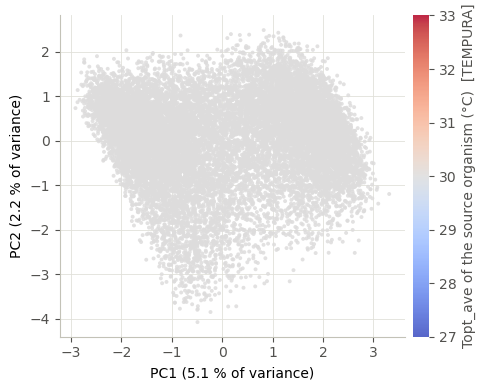

In [43]:
ALPHABET = "-ACDEFGHIKLMNPQRSTVWY"   # one-hot states; any other character (X, B, Z, ...) counts as a gap
MAX_GAP_FRACTION = 0.5     # alignment only: leave out rows with more gaps than this (fragments dominate the PCs)
MAX_FIT_SEQS = 20_000      # the PCA is fitted on a random subset of at most this many sequences ...
CHUNK = 10_000             # ... and then every sequence is projected, this many at a time
COLOR_CENTER = 45.0        # Topt (°C) at the neutral middle of the colour scale: blue below, red above
INK, INK_2, GRID, AXIS = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"

pca_df = seqs

# A2M/A3M: lower-case letters and '.' are insertions, not alignment columns -> drop them
cols = pca_df["sequence"].str.replace(r"[a-z.]", "", regex=True)


L, q = len(cols.iloc[0]), len(ALPHABET)
lut = np.zeros(256, dtype=np.int64)                 # unknown characters -> state 0 (gap)
for i, a in enumerate(ALPHABET):
    lut[ord(a)] = i
codes = lut[np.frombuffer("".join(cols).encode("ascii", "replace"), dtype=np.uint8)].reshape(len(cols), L)
keep_rows = (codes == 0).mean(axis=1) <= MAX_GAP_FRACTION
if (~keep_rows).any():
    print(f"left out {(~keep_rows).sum():,} sequences with more than {MAX_GAP_FRACTION:.0%} gaps")
codes, pca_df = codes[keep_rows], pca_df[keep_rows].reset_index(drop=True)

def features(rows):
    """One-hot encoding (L x 21 columns) of the given rows."""
    X = np.zeros((len(rows), L * q), dtype=np.float32)
    X[np.arange(len(rows))[:, None], np.arange(L) * q + codes[rows]] = 1
    return X

mode = f"one-hot alignment, {L} columns"

n = len(pca_df)
if n < 3:
    raise ValueError("need at least 3 retained sequences for a PCA")
rng = np.random.default_rng(0)
fit_rows = np.sort(rng.choice(n, size=min(n, MAX_FIT_SEQS), replace=False))
pca = PCA(n_components=2, svd_solver="randomized", random_state=0).fit(features(fit_rows))
pcs = np.vstack([pca.transform(features(np.arange(s, min(s + CHUNK, n)))) for s in range(0, n, CHUNK)])
pca_df["PC1"], pca_df["PC2"] = pcs[:, 0], pcs[:, 1]
var = 100 * pca.explained_variance_ratio_

rho = {pc: pca_df[pc].rank().corr(pca_df["Topt_ave"].rank()) for pc in ("PC1", "PC2")}
print(f"PCA of {n:,} sequences ({mode}); Spearman rho with Topt_ave: "
      f"PC1 {rho['PC1']:.2f}, PC2 {rho['PC2']:.2f}")

# --- plot ------------------------------------------------------------------------------------
t = pca_df["Topt_ave"].to_numpy()
vmin, vmax = t.min(), t.max()
norm = (TwoSlopeNorm(vmin=vmin, vcenter=COLOR_CENTER, vmax=vmax) if vmin < COLOR_CENTER < vmax
        else Normalize(vmin=vmin, vmax=vmax))
order = np.argsort(np.abs(t - COLOR_CENTER))      # most extreme temperatures drawn last, i.e. on top

fig, ax = plt.subplots(figsize=(5, 4))
sc = ax.scatter(pca_df["PC1"].to_numpy()[order], pca_df["PC2"].to_numpy()[order], c=t[order],
                cmap="coolwarm", norm=norm, s=8, alpha=0.85, linewidths=0, rasterized=True, zorder=2)

cbar = fig.colorbar(sc, ax=ax, pad=0.02)
cbar.set_label("Topt_ave of the source organism (°C)  [TEMPURA]", color=INK_2)
cbar.outline.set_visible(False)
cbar.ax.tick_params(colors=INK_2)
ax.set_xlabel(f"PC1 ({var[0]:.1f} % of variance)")
ax.set_ylabel(f"PC2 ({var[1]:.1f} % of variance)")
ax.grid(color=GRID, lw=0.6, zorder=0)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_color(AXIS)
ax.tick_params(colors=INK_2)

fig.tight_layout()
#fig_path = Path(f"{stem}_tempura_pca.png")
#fig.savefig(fig_path, dpi=200, bbox_inches="tight")
#print(f"Saved {fig_path}")
plt.show()

## Comparison with natural seqs

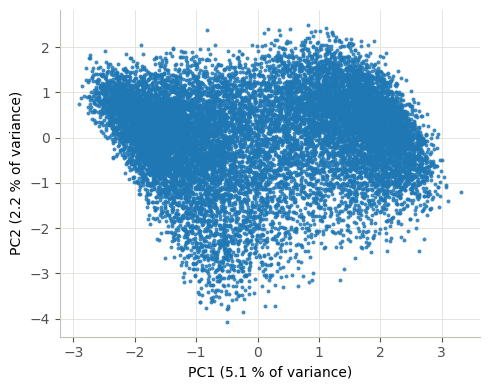

In [ ]:

pca_df = seqs

# A2M/A3M: lower-case letters and '.' are insertions, not alignment columns -> drop them
cols = pca_df["sequence"].str.replace(r"[a-z.]", "", regex=True)


L, q = len(cols.iloc[0]), len(ALPHABET)
lut = np.zeros(256, dtype=np.int64)                 # unknown characters -> state 0 (gap)
for i, a in enumerate(ALPHABET):
    lut[ord(a)] = i
codes = lut[np.frombuffer("".join(cols).encode("ascii", "replace"), dtype=np.uint8)].reshape(len(cols), L)
keep_rows = (codes == 0).mean(axis=1) <= MAX_GAP_FRACTION
if (~keep_rows).any():
    print(f"left out {(~keep_rows).sum():,} sequences with more than {MAX_GAP_FRACTION:.0%} gaps")
codes, pca_df = codes[keep_rows], pca_df[keep_rows].reset_index(drop=True)

mode = f"one-hot alignment, {L} columns"

n = len(pca_df)
if n < 3:
    raise ValueError("need at least 3 retained sequences for a PCA")
rng = np.random.default_rng(0)
fit_rows = np.sort(rng.choice(n, size=min(n, MAX_FIT_SEQS), replace=False))
pca = PCA(n_components=2, svd_solver="randomized", random_state=0).fit(features(fit_rows))
pcs = np.vstack([pca.transform(features(np.arange(s, min(s + CHUNK, n)))) for s in range(0, n, CHUNK)])
pca_df["PC1"], pca_df["PC2"] = pcs[:, 0], pcs[:, 1]
var = 100 * pca.explained_variance_ratio_

FASTA_NAT = Path("./data/processed_new/jdomain.aligned.maxgap50.fasta.fasta")  

records_nat = read_fasta(FASTA_NAT)
seqs_nat = pd.DataFrame(records_nat, columns=["header", "sequence"])
pca_nat_df = seqs_nat
features_nat = pca.transform(features(seqs_nat))


# --- plot ------------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(5, 4))
sc = ax.scatter(pca_df["PC1"].to_numpy()[order], pca_df["PC2"].to_numpy()[order], s=8, alpha=0.85, linewidths=0, rasterized=True, zorder=2)
ax.set_xlabel(f"PC1 ({var[0]:.1f} % of variance)")
ax.set_ylabel(f"PC2 ({var[1]:.1f} % of variance)")
ax.grid(color=GRID, lw=0.6, zorder=0)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_color(AXIS)
ax.tick_params(colors=INK_2)

fig.tight_layout()
plt.show()